# 1. Simulation Walkthrough

A step-by-step look at what `CarlaGymEnv` is actually doing under the hood:
the network starts empty, we push traffic through it, and we watch queues,
throughput, latency and congestion develop over time.

This notebook uses the synthetic Poisson traffic generator (no dataset
needed) so it runs standalone.

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from carla_gym.env import CarlaGymEnv
from carla_gym.utils.visualization import NetworkVisualizer

plt.rcParams["figure.dpi"] = 100
np.random.seed(0)

## Build the environment and look at the empty network

nodes=9  links=12
observation shape=(33,)  action shape=(12,)


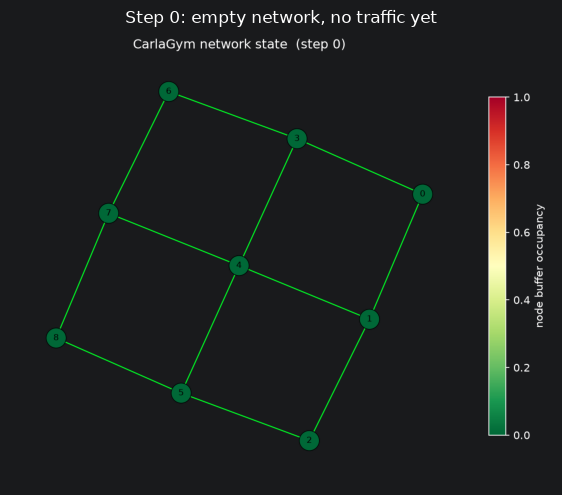

In [2]:
env = CarlaGymEnv(topology="grid", num_nodes=9, link_capacity=30, node_buffer=120,
                  bandwidth_budget=0.8, max_steps=150, seed=0)
obs, info = env.reset(seed=0)

print(f"nodes={env.num_nodes}  links={env.num_edges}")
print(f"observation shape={obs.shape}  action shape={env.action_space.shape}")

viz = NetworkVisualizer(env.network)
viz.render(step=0, save_path="notebooks/_tmp_empty.png")
plt.figure(figsize=(7, 6))
plt.imshow(plt.imread("notebooks/_tmp_empty.png"))
plt.axis("off")
plt.title("Step 0: empty network, no traffic yet")
plt.show()

## Run a congestion-aware policy and log every step

We use the `queue_proportional` heuristic from `examples/random_agent_test.py`
so the network actually experiences realistic load without training anything.

In [3]:
from examples.random_agent_test import policy_queue_proportional

rows = []
obs, _ = env.reset(seed=0)
rng = np.random.default_rng(0)
for t in range(150):
    action = policy_queue_proportional(env, obs, rng)
    obs, reward, terminated, truncated, info = env.step(action)
    rows.append({
        "step": t, "reward": reward,
        "throughput": info["reward_throughput"],
        "delay": info["reward_delay"],
        "loss": info["reward_loss"],
        "latency_steps": info["mean_latency_steps"],
        "backlog_units": info["backlog_units"],
        "mean_link_utilization": info["mean_link_utilization"],
    })
    if terminated or truncated:
        break

log = pd.DataFrame(rows)
log.tail()

,step,reward,throughput,delay,loss,latency_steps,backlog_units,mean_link_utilization
145,145,0.110526,0.708494,0.441408,0.377264,4.000000,582.922947,0.366696
146,146,0.281847,0.777494,0.495223,0.248036,3.750000,580.387171,0.472053
147,147,0.642886,1.000000,0.620593,0.046817,4.833333,554.102824,0.428963
148,148,0.173498,0.676914,0.946533,0.030150,6.133333,594.580195,0.440502
149,149,0.500000,1.000000,1.000000,0.000000,11.500000,593.285672,0.475100


## Queue backlog and link utilization over time

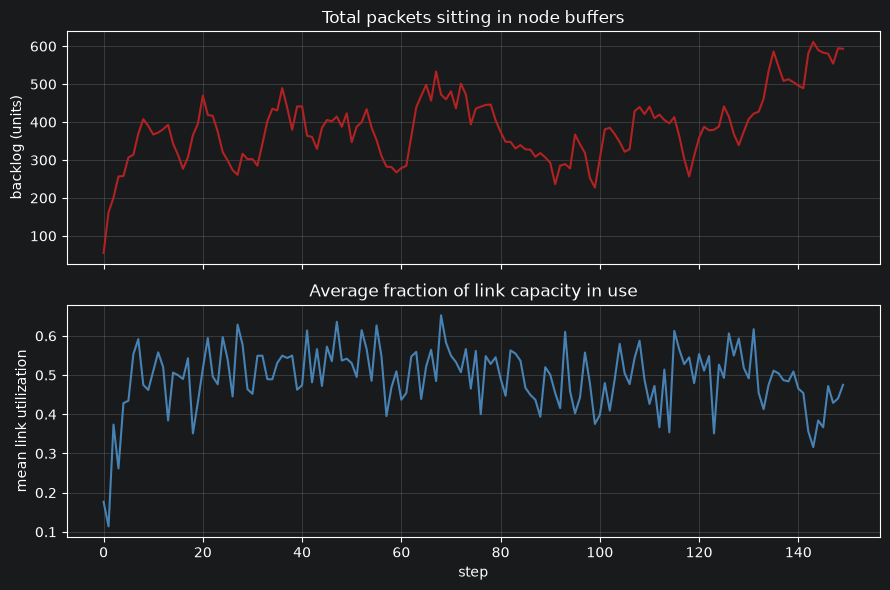

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(log["step"], log["backlog_units"], color="firebrick")
axes[0].set_ylabel("backlog (units)")
axes[0].set_title("Total packets sitting in node buffers")
axes[0].grid(alpha=0.3)

axes[1].plot(log["step"], log["mean_link_utilization"], color="steelblue")
axes[1].set_ylabel("mean link utilization")
axes[1].set_xlabel("step")
axes[1].set_title("Average fraction of link capacity in use")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## The three reward components over time

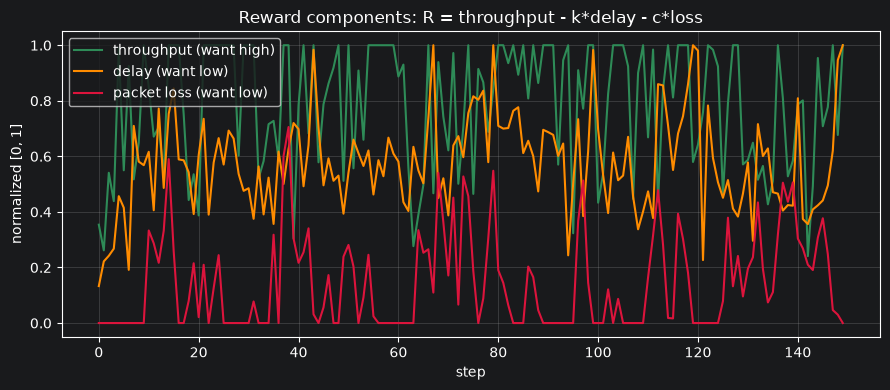

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(log["step"], log["throughput"], label="throughput (want high)", color="seagreen")
ax.plot(log["step"], log["delay"], label="delay (want low)", color="darkorange")
ax.plot(log["step"], log["loss"], label="packet loss (want low)", color="crimson")
ax.set_xlabel("step")
ax.set_ylabel("normalized [0, 1]")
ax.set_title("Reward components: R = throughput - k*delay - c*loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Network state: healthy vs congested

Render the network at an early (lightly loaded) step and a later
(more congested) step, side by side. Edge color/width encodes link
utilization (green -> red), node color/size encodes buffer occupancy.

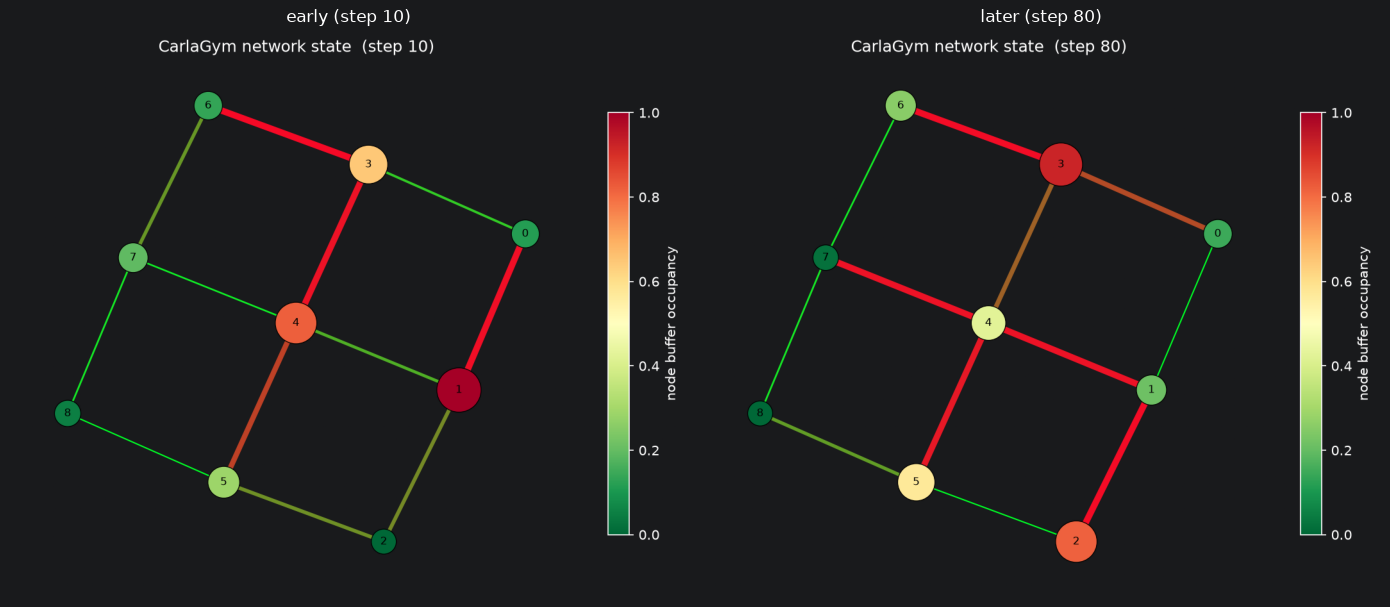

In [8]:
env.reset(seed=0)
rng = np.random.default_rng(0)
obs = env._observe()
snapshots = {}
for t in range(150):
    action = policy_queue_proportional(env, obs, rng)
    obs, reward, terminated, truncated, info = env.step(action)
    if t == 9:
        viz.render(step=t + 1, save_path="notebooks/_tmp_early.png")
        snapshots["early (step 10)"] = "notebooks/_tmp_early.png"
    if t == 79:
        viz.render(step=t + 1, save_path="notebooks/_tmp_late.png")
        snapshots["later (step 80)"] = "notebooks/_tmp_late.png"
    if terminated or truncated:
        break

fig, axes = plt.subplots(1, len(snapshots), figsize=(7 * len(snapshots), 6))
if len(snapshots) == 1:
    axes = [axes]
for ax, (title, path) in zip(axes, snapshots.items()):
    ax.imshow(plt.imread(path))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Zero-bandwidth stress test

To see real congestion build, starve the network entirely (action = 0
everywhere) for a stretch of steps and watch the backlog climb and
every link turn red.

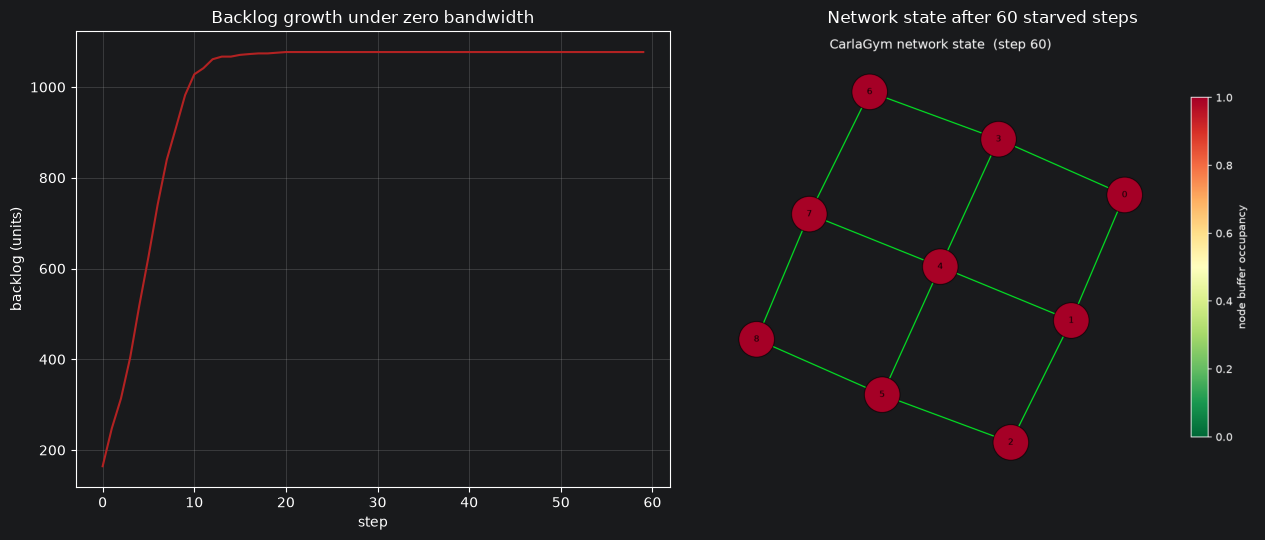

In [9]:
env.reset(seed=1)
backlog_trace = []
for t in range(60):
    action = np.zeros(env.num_edges, dtype=np.float32)
    obs, reward, terminated, truncated, info = env.step(action)
    backlog_trace.append(info["backlog_units"])

viz.render(step=60, save_path="notebooks/_tmp_starved.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].plot(backlog_trace, color="firebrick")
axes[0].set_title("Backlog growth under zero bandwidth")
axes[0].set_xlabel("step")
axes[0].set_ylabel("backlog (units)")
axes[0].grid(alpha=0.3)

axes[1].imshow(plt.imread("notebooks/_tmp_starved.png"))
axes[1].set_title("Network state after 60 starved steps")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [8]:
# cleanup temp render files
import glob
for f in glob.glob("notebooks/_tmp_*.png"):
    os.remove(f)